# 02 Regression - Homework - Ahmed Elsherif

## Setup

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-09-27 18:00:00--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.03s   

2026-09-27 18:00:00 (20.5 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



In [4]:
data = pd.read_csv('car_fuel_efficiency_2026.csv')

## Preparing the dataset

Use only the following columns:

- `engine_displacement`,
- `horsepower`,
- `vehicle_weight`,
- `model_year`,
- `fuel_efficiency_mpg`


In [5]:
df = data [['engine_displacement',
           'horsepower',
           'vehicle_weight',
           'model_year',
           'fuel_efficiency_mpg']]

## EDA

- Look at the `fuel_efficiency_mpg` variable. Does it have a long tail?
- **Note:** It has a tail but not very long, this looks rpughly like normal distribution.

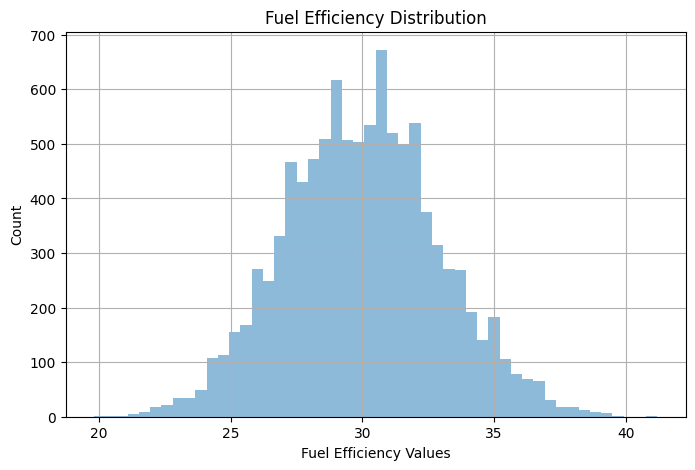

In [9]:
plt.figure(figsize=(8,5))
df["fuel_efficiency_mpg"].hist(
    bins=50,
    alpha=0.5,
    label="fuel_efficiency_mpg"
)

plt.title("Fuel Efficiency Distribution")
plt.xlabel("Fuel Efficiency Values")
plt.ylabel("Count")

plt.show();

In [10]:
df["fuel_efficiency_mpg"].describe()

,fuel_efficiency_mpg
count,10000.000000
mean,29.997700
std,2.930245
min,19.800000
25%,28.000000
50%,30.000000
75%,31.900000
max,41.200000


## Question 1

- There's one column with missing values. What is it?

- **Answer:** `horsepower`

In [30]:
cols_with_missing_values = df.isnull().sum()[df.isnull().sum()>0]
print(f"The column with missing values is: {cols_with_missing_values}")

print("\n\nMissing values per column:\n", df.isnull().sum())


The column with missing values is: horsepower    877
dtype: int64


Missing values per column:
 engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64


## Question 2

- What's the median (50% percentile) for variable `horsepower`?

- **Answer:** `254`


In [39]:
horsepower_median = int(df['horsepower'].median())

print("horsepower median is:",horsepower_median)

print("\n\nhorsepower statistical summary:\n", df['horsepower'].describe().round())

horsepower median is: 254


horsepower statistical summary:
 count    9123.0
mean      254.0
std        23.0
min       171.0
25%       239.0
50%       254.0
75%       270.0
max       334.0
Name: horsepower, dtype: float64


## Prepare and split the dataset

- Shuffle the filtered dataset and create the split exactly as in the lecture:

```python
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

For Q5, repeat the same block with each listed seed. For Q6, use seed 9.
```

In [40]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

## Question 3

- We need to deal with missing values for the column from Q1.
- We have two options: fill it with 0 or with the mean of this variable.
- Try both options. For each, train a linear regression model without regularization using the code from the lessons.
- For computing the mean, use the training only!
- Use the validation dataset to evaluate the models and compare the RMSE of each option.
- Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.


### Which option gives better RMSE?

  - Options:

    - `With 0`
    - `With mean`
    - `Both are equally good`
